In [4]:
# 202431052_Anfal Ridho Hanif
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [5]:
# 202431052_Anfal Ridho Hanif
df = pd.read_csv('Health_Insurance_Lead_Prediction_Raw_Data.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50882 entries, 0 to 50881
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       50882 non-null  int64  
 1   City_Code                50882 non-null  object 
 2   Region_Code              50882 non-null  int64  
 3   Accomodation_Type        50882 non-null  object 
 4   Reco_Insurance_Type      50882 non-null  object 
 5   Upper_Age                50882 non-null  int64  
 6   Lower_Age                50882 non-null  int64  
 7   Is_Spouse                50882 non-null  object 
 8   Health Indicator         39191 non-null  object 
 9   Holding_Policy_Duration  30631 non-null  object 
 10  Holding_Policy_Type      30631 non-null  float64
 11  Reco_Policy_Cat          50882 non-null  int64  
 12  Reco_Policy_Premium      50882 non-null  float64
 13  Response                 50882 non-null  int64  
dtypes: float64(2), int64(6

In [9]:
# 202431052_Anfal Ridho Hanif
df.describe(include="all")
print(df.isna().sum())
kolom_kategorik = df.select_dtypes(include=['object']).columns
for col in kolom_kategorik:
    print(f"- {col}: {df[col].unique()}")
    
    
    
kolom_angka = df.select_dtypes(include=['number']).columns

ID                             0
City_Code                      0
Region_Code                    0
Accomodation_Type              0
Reco_Insurance_Type            0
Upper_Age                      0
Lower_Age                      0
Is_Spouse                      0
Health Indicator           11691
Holding_Policy_Duration    20251
Holding_Policy_Type        20251
Reco_Policy_Cat                0
Reco_Policy_Premium            0
Response                       0
dtype: int64
- City_Code: ['C3' 'C5' 'C24' 'C8' 'C9' 'C1' 'C15' 'C28' 'C27' 'C7' 'C20' 'C25' 'C4'
 'C2' 'C34' 'C10' 'C17' 'C18' 'C16' 'C29' 'C33' 'C26' 'C19' 'C6' 'C12'
 'C13' 'C11' 'C14' 'C22' 'C23' 'C21' 'C36' 'C32' 'C30' 'C35' 'C31']
- Accomodation_Type: ['Rented' 'Owned']
- Reco_Insurance_Type: ['Individual' 'Joint']
- Is_Spouse: ['No' 'Yes']
- Health Indicator: ['X1' 'X2' nan 'X4' 'X3' 'X6' 'X5' 'X8' 'X7' 'X9']
- Holding_Policy_Duration: ['14+' nan '1.0' '3.0' '5.0' '9.0' '14.0' '7.0' '2.0' '11.0' '10.0' '8.0'
 '6.0' '4.0' '13.

In [12]:
# 202431052_Anfal Ridho Hanif
kolom_angka = df.select_dtypes(include=['number']).columns

for col in kolom_angka:
    df[col] = df[col].fillna(df[col].mean())
    
for col in kolom_kategorik:
    df[col] = df[col].fillna(df[col].mode()[0])
    
print(df.isna().sum().sum())


ID                             0
City_Code                      0
Region_Code                    0
Accomodation_Type              0
Reco_Insurance_Type            0
Upper_Age                      0
Lower_Age                      0
Is_Spouse                      0
Health Indicator           11691
Holding_Policy_Duration    20251
Holding_Policy_Type        20251
Reco_Policy_Cat                0
Reco_Policy_Premium            0
Response                       0
dtype: int64



=== Informasi Data Setelah Hapus Duplikat ===
<class 'pandas.core.frame.DataFrame'>
Int64Index: 50882 entries, 0 to 50881
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       50882 non-null  int64  
 1   City_Code                50882 non-null  object 
 2   Region_Code              50882 non-null  int64  
 3   Accomodation_Type        50882 non-null  object 
 4   Reco_Insurance_Type      50882 non-null  object 
 5   Upper_Age                50882 non-null  int64  
 6   Lower_Age                50882 non-null  int64  
 7   Is_Spouse                50882 non-null  object 
 8   Health Indicator         39191 non-null  object 
 9   Holding_Policy_Duration  30631 non-null  object 
 10  Holding_Policy_Type      30631 non-null  float64
 11  Reco_Policy_Cat          50882 non-null  int64  
 12  Reco_Policy_Premium      50882 non-null  float64
 13  Response                 5088

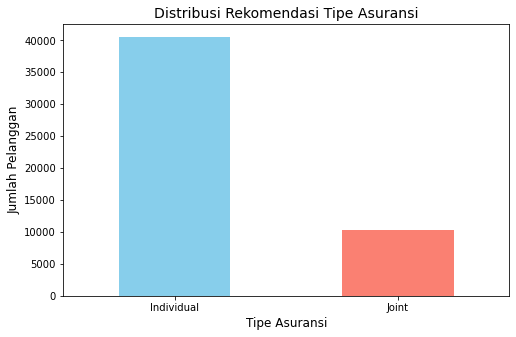

In [10]:
# 202431052_Anfal Ridho Hanif
df = df.drop_duplicates()
print("\n=== Informasi Data Setelah Hapus Duplikat ===")
df.info()

plt.figure(figsize=(8, 5))
df['Reco_Insurance_Type'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])

plt.title('Distribusi Rekomendasi Tipe Asuransi', fontsize=14)
plt.xlabel('Tipe Asuransi', fontsize=12)
plt.ylabel('Jumlah Pelanggan', fontsize=12)
plt.xticks(rotation=0) # Agar teks di sumbu X tidak miring

plt.show()